# Tahap 3 KDD - Transformation (Ekstraksi Fitur)

Mengubah tiap citra menjadi vektor fitur numerik. Dasar: jurnal Sitompul (2020) - LBP.

| Grup fitur | Jumlah | Cara kerja | Dasar dari jurnal |
|---|---|---|---|
| `lbp256_*` | 256 | LBP default P=8, R=1; histogram 256-bin ternormalisasi | Pers. (1)-(2), 256-bin descriptor |
| `lbpms_*` | 10+18+26 = 54 | LBP uniform melingkar (8,1), (16,2), (24,3) | Circular neighborhood (P,R) |
| `dir_*` | 5 | Proporsi piksel tepi total dan per arah | Kode arah 2/3/4/5 dan K(n), Pers. (3) |
| `glcm_*` | 4 | Contrast, homogeneity, energy, correlation (jarak 1 & 3, 4 sudut) | Tambahan (analisis tekstur) |

**Total: 319 fitur per foto.**

Skenario ablasi untuk studi Tahap 4:

- **A** - LBP256 (setia pada jurnal)
- **B** - LBP multi-skala
- **C** - B + arah
- **D** - lengkap (B + arah + GLCM)

Normalisasi (StandardScaler) **tidak** dilakukan di sini - nanti di dalam pipeline pada Tahap 4, agar statistiknya hanya dihitung dari data latih per fold.

In [1]:
%matplotlib inline

import os
import sys
from pathlib import Path

# Pastikan kernel berada di folder induk proyek agar `import config` berfungsi
HERE = Path.cwd().resolve()
ROOT = HERE.parent if HERE.name == "notebooks" else HERE
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import config as C

print("ROOT      :", ROOT)
print("Folder data:", C.RAW_DIR)
print("Kelas     :", C.CLASSES)

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from skimage.feature import graycomatrix, graycoprops, local_binary_pattern

ROOT      : D:\Perkuliahan\Machine Learning teori\Ban_Motor
Folder data: D:\Perkuliahan\Machine Learning teori\Ban_Motor\data\raw
Kelas     : ['baik', 'sedang', 'aus']


In [2]:
def lbp256(gray):
    """LBP dasar 3x3 (P=8,R=1), histogram 256-bin -> seperti jurnal (Pers. 1 & 2)."""
    lbp = local_binary_pattern(gray, 8, 1, method="default")
    h, _ = np.histogram(lbp, bins=256, range=(0, 256))
    return h / h.sum()


def lbp_multiscale(gray):
    """LBP uniform melingkar (P,R) berbeda -> menangkap alur skala besar."""
    feats = []
    for P, R in C.LBP_MS:
        lbp = local_binary_pattern(gray, P, R, method="uniform")
        h, _ = np.histogram(lbp, bins=P + 2, range=(0, P + 2))
        feats.append(h / h.sum())
    return np.concatenate(feats)


def direction_stats(gray):
    """Analogi kode arah jurnal (2=vertikal, 3=diagonal kanan, 4=horizontal, 5=diagonal kiri).
    K(n) = jumlah piksel tepi berarah n / jumlah piksel total (Pers. 3)."""
    edges = cv2.Canny(gray, 60, 150) > 0
    gx = cv2.Sobel(gray, cv2.CV_32F, 1, 0, ksize=3)
    gy = cv2.Sobel(gray, cv2.CV_32F, 0, 1, ksize=3)
    ang = (np.degrees(np.arctan2(gy, gx)) % 180)[edges]      # arah gradien 0..180
    n = gray.size
    vert = np.sum((ang < 22.5) | (ang >= 157.5))             # gradien horizontal -> garis vertikal
    diag_r = np.sum((ang >= 22.5) & (ang < 67.5))            # garis "/"
    horiz = np.sum((ang >= 67.5) & (ang < 112.5))            # garis horizontal
    diag_l = np.sum((ang >= 112.5) & (ang < 157.5))          # garis "\"
    return np.array([edges.sum() / n, vert / n, diag_r / n, horiz / n, diag_l / n])


def glcm_stats(gray):
    g = (gray // 4).astype(np.uint8)                         # 64 level -> GLCM ringan
    m = graycomatrix(g, distances=[1, 3], angles=[0, np.pi / 4, np.pi / 2, 3 * np.pi / 4],
                     levels=64, symmetric=True, normed=True)
    return np.array([graycoprops(m, p).mean()
                     for p in ("contrast", "homogeneity", "energy", "correlation")])


def extract_all(gray):
    """Satu vektor fitur; nama kolom berawalan grup (lbp256_, lbpms_, dir_, glcm_)."""
    a, b, c, d = lbp256(gray), lbp_multiscale(gray), direction_stats(gray), glcm_stats(gray)
    names = ([f"lbp256_{i}" for i in range(len(a))] + [f"lbpms_{i}" for i in range(len(b))]
             + ["dir_edge", "dir_vert", "dir_diagr", "dir_horiz", "dir_diagl"]
             + ["glcm_contrast", "glcm_homog", "glcm_energy", "glcm_corr"])
    return names, np.concatenate([a, b, c, d])


# Skenario fitur untuk studi ablasi (seberapa besar tiap grup fitur berkontribusi)
FEATURE_SETS = {
    "A_LBP256 (jurnal)": ["lbp256_"],
    "B_LBP multi-skala": ["lbpms_"],
    "C_LBP-MS + arah": ["lbpms_", "dir_"],
    "D_Lengkap": ["lbpms_", "dir_", "glcm_"],
}

### Uji cepat pada satu foto

In [3]:
df_sp = pd.read_csv(C.PROCESSED_DIR / "splits.csv")
row0 = df_sp.iloc[0]
p = C.INTERIM_DIR / "gray" / row0["split"] / row0["label"] / (Path(row0["path"]).stem + ".png")
gray = cv2.imread(str(p), 0)
names, vec = extract_all(gray)

print("foto       :", p.name, f"({row0['label']}, {row0['split']})")
print("jumlah fitur:", len(names), "| panjang vektor:", vec.shape)
print("nama kolom  :", names[:3], "...", names[-4:])
print("ada NaN     :", bool(np.isnan(vec).any()))

foto       : ban_bagus_1.png (baik, train)
jumlah fitur: 319 | panjang vektor: (319,)
nama kolom  : ['lbp256_0', 'lbp256_1', 'lbp256_2'] ... ['glcm_contrast', 'glcm_homog', 'glcm_energy', 'glcm_corr']
ada NaN     : False


### Ekstraksi seluruh dataset

In [4]:
rows = []
for i, (_, r) in enumerate(df_sp.iterrows()):
    name = Path(r["path"]).stem + ".png"
    gray = cv2.imread(str(C.INTERIM_DIR / "gray" / r["split"] / r["label"] / name), 0)
    if gray is None:
        print("gagal baca:", r["path"])
        continue
    names, vec = extract_all(gray)
    rows.append([r["split"], r["label"], name, *vec])
    if (i + 1) % 100 == 0:
        print(f"... {i + 1}/{len(df_sp)} foto")

features = pd.DataFrame(rows, columns=["split", "label", "file", *names])
features.to_csv(C.PROCESSED_DIR / "features.csv", index=False)
print("features.csv:", features.shape)

... 100/529 foto


... 200/529 foto


... 300/529 foto


... 400/529 foto


... 500/529 foto


features.csv: (529, 322)


### Pemeriksaan kualitas fitur

In [5]:
num = features[names]
print("jumlah NaN        :", int(num.isna().sum().sum()))
print("jumlah non-finite :", int((~np.isfinite(num.to_numpy())).sum()))
print("fitur konstan      :", int((num.nunique() <= 1).sum()), "dari", len(names))
display(features.groupby(["label"]).size().to_frame("jumlah foto"))

jumlah NaN        : 0
jumlah non-finite : 0
fitur konstan      : 1 dari 319


,jumlah foto
label,
aus,212
baik,189
sedang,128


,dir_edge,dir_vert,dir_diagr,dir_horiz,dir_diagl,glcm_contrast,glcm_homog,glcm_energy,glcm_corr
label,,,,,,,,,
baik,0.1426,0.0413,0.0393,0.0166,0.0454,22.7402,0.3926,0.0679,0.8870
sedang,0.1568,0.0460,0.0433,0.0210,0.0465,21.1406,0.3811,0.0695,0.8838
aus,0.1821,0.0498,0.0533,0.0265,0.0525,20.9414,0.3609,0.0625,0.8638


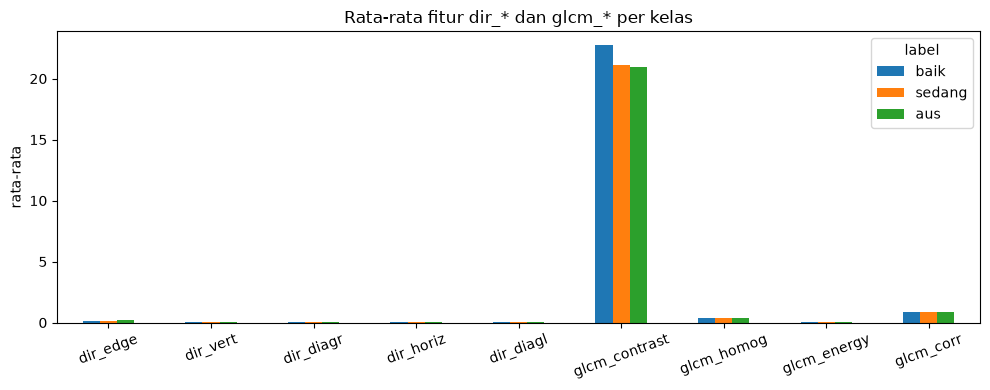

In [6]:
stat_cols = [c for c in names if c.startswith("dir_") or c.startswith("glcm_")]
means = features.groupby("label")[stat_cols].mean().loc[C.CLASSES]
display(means.round(4))

means.T.plot(kind="bar", figsize=(10, 4), rot=20)
plt.ylabel("rata-rata")
plt.title("Rata-rata fitur dir_* dan glcm_* per kelas")
plt.tight_layout()
plt.show()

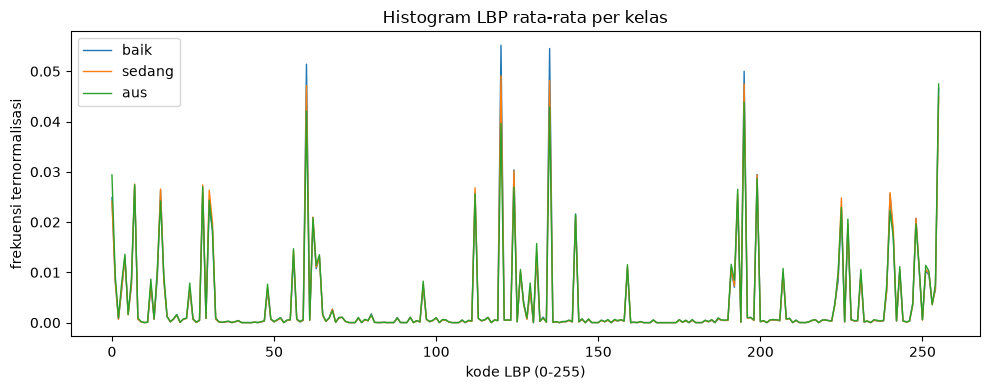

In [7]:
lbp_cols = [c for c in names if c.startswith("lbp256_")]
m = features.groupby("label")[lbp_cols].mean().loc[C.CLASSES]

plt.figure(figsize=(10, 4))
for label in C.CLASSES:
    plt.plot(range(256), m.loc[label].to_numpy(), label=label, lw=1)
plt.xlabel("kode LBP (0-255)")
plt.ylabel("frekuensi ternormalisasi")
plt.title("Histogram LBP rata-rata per kelas")
plt.legend()
plt.tight_layout()
plt.show()

## Periksa sebelum lanjut (Tahap 4)

- [ ] Tidak ada NaN / nilai non-finite di `features.csv`.
- [ ] Tiap grup fitur bervariasi antarkelas (bandingkan rata-rata per kelas di atas).
- [ ] Rata-rata histogram LBP kelas "aus" berbeda dari "baik" (alur hilang = tekstur berubah).
- [ ] Skenario ablasi `FEATURE_SETS` (A-D) siap dipakai untuk tuning KNN/SVM/RF.